# Consistency Flow Matching：二维输运验证实验

本实验按论文训练思路重新设计，并保留具有解析解的二维高斯基准。全部代码、训练、指标和图片都包含在 notebook 中。

实验回答三个问题：

1. Consistency-FM 能否让生成 ODE 轨迹变直？
2. 轨迹变直后，生成终点分布是否仍正确？
3. 真实边界监督和速度一致性项分别起什么作用？

本文采用单段二维 MLP 验证，属于基于论文损失思想的可解释实验，不是图像配置的逐行复现。参考论文：[Consistency Flow Matching: Defining Straight Flows with Velocity Consistency](https://arxiv.org/abs/2407.02398)。

## 1. 分布、coupling 与六组对照

$$
X_0\sim\mathcal N(0,I_2),\qquad
X_1\sim\mathcal N\!\left(
\begin{bmatrix}2\\-1\end{bmatrix},
\operatorname{diag}(0.65^2,1.55^2)
\right).
$$

| 组别 | 方法 | 作用 |
|---|---|---|
| A | 解析 independent FM | 正确但弯曲的理论边缘流 |
| B | 标准 FM，independent coupling | 神经网络基线 |
| C | Stage-1 后仅终点一致性 | 检查终点一致性 |
| D | Stage-1 后终点 + 速度一致性 | 完整单段 CFM |
| E | Stage-1 后取消真实边界监督 | 检查 boundary 的作用 |
| F | 标准 FM，OT coupling | 正确直线输运对照 |

C、D、E 从完全相同的 Stage-1 权重出发，并重置为相同随机种子，从而使用相同的样本、时间和初始化。

In [1]:
from pathlib import Path
import copy
import json
import math
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32
SEED = 42

BATCH_SIZE = 512
STAGE1_STEPS = 4_000
STAGE2_STEPS = 4_000
LEARNING_RATE = 1e-3
DELTA = 1e-3
ALPHA = 1e-5
BOUNDARY = 0.9
NUM_SEGMENTS = 1

N_TEST = 2_048
N_PATHS = 30
N_STEPS = 128

MU = torch.tensor([2.0, -1.0], device=DEVICE, dtype=DTYPE)
SIGMA = torch.tensor([0.65, 1.55], device=DEVICE, dtype=DTYPE)
OUTPUT_DIR = Path("cfm_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.25})
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("Output directory:", OUTPUT_DIR.resolve())

PyTorch: 2.5.1
Device: cuda
Output directory: /home/zhangjinrui/my_program_code/Data_Processing/python/E2E/DLP/Diffuison/cfm_outputs


## 2. 解析 independent FM 与 OT 基准

对 independent coupling，最优边缘速度逐维为

$$
u_i(x,t)=\mu_i+
\frac{t\sigma_i^2-(1-t)}{(1-t)^2+t^2\sigma_i^2}(x_i-t\mu_i),
$$

对应解析轨迹

$$
x_{t,i}=t\mu_i+\sqrt{(1-t)^2+t^2\sigma_i^2}\,x_{0,i}.
$$

它到达正确目标分布，但中间一般弯曲。高斯 OT coupling 取

$$X_1=\mu+\sigma\odot X_0,$$

于是 $x_t=(1-t)X_0+tX_1$ 是正确的匀速直线输运。

In [2]:
def sample_pairs(batch_size, coupling="independent"):
    x0 = torch.randn(batch_size, 2, device=DEVICE, dtype=DTYPE)
    if coupling == "independent":
        x1 = MU+SIGMA*torch.randn_like(x0)
    elif coupling == "ot":
        x1 = MU+SIGMA*x0
    else:
        raise ValueError(coupling)
    return x0, x1


def interpolate(x0, x1, t):
    return (1-t)*x0+t*x1


def analytic_fm_velocity(x, t):
    variance = (1-t).square()+(t*SIGMA).square()
    coefficient = (t*SIGMA.square()-(1-t))/variance
    return MU+coefficient*(x-t*MU)


def analytic_ot_velocity(x, t):
    # 由 x_t=t*mu+[(1-t)+t*sigma]x_0 反解 x_0。
    scale_t = (1-t)+t*SIGMA
    x0 = (x-t*MU)/scale_t
    return MU+(SIGMA-1)*x0


def analytic_fm_path(x0, times):
    result = []
    for time_value in times:
        t = torch.as_tensor(time_value, device=DEVICE, dtype=DTYPE)
        scale = torch.sqrt((1-t).square()+(t*SIGMA).square())
        result.append(t*MU+scale*x0)
    return torch.stack(result)


def analytic_ot_path(x0, times):
    x1 = MU+SIGMA*x0
    return torch.stack([(1-float(t))*x0+float(t)*x1 for t in times])

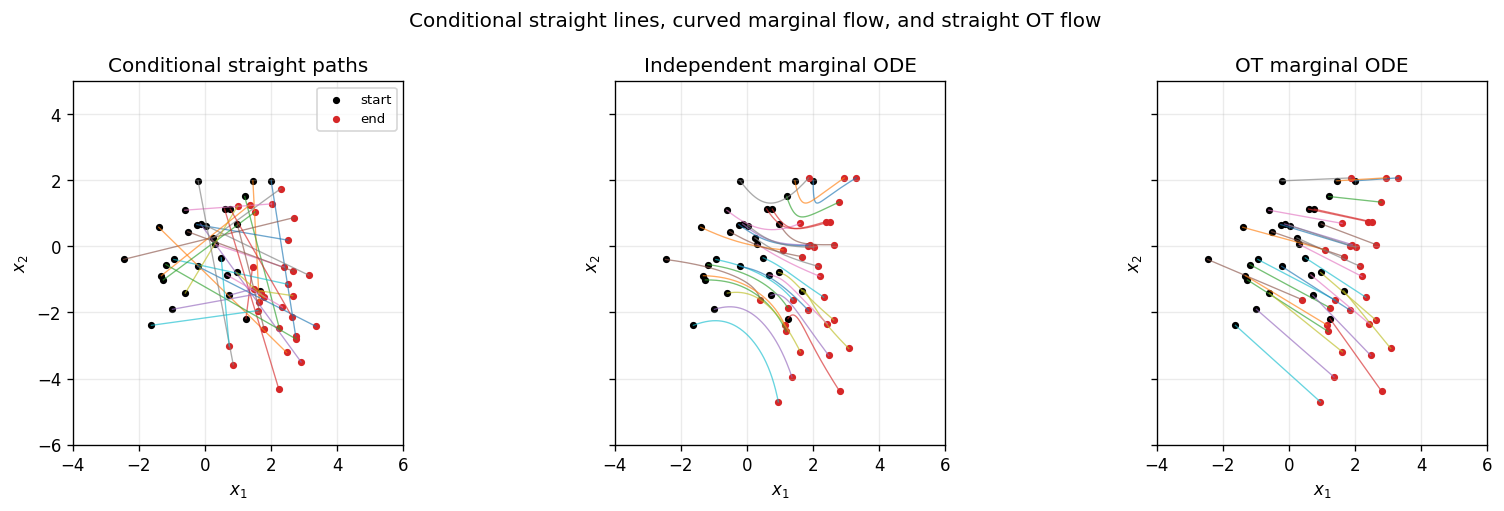

In [3]:
set_seed(SEED+1)
visual_x0, visual_x1 = sample_pairs(N_PATHS, "independent")
visual_times = torch.linspace(0, 1, N_STEPS+1, device=DEVICE)
conditional_paths = torch.stack([
    interpolate(visual_x0, visual_x1, t) for t in visual_times
])
independent_paths = analytic_fm_path(visual_x0, visual_times)
ot_paths = analytic_ot_path(visual_x0, visual_times)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), sharex=True, sharey=True)
for ax, paths, title in zip(
    axes,
    [conditional_paths, independent_paths, ot_paths],
    ["Conditional straight paths", "Independent marginal ODE", "OT marginal ODE"],
):
    values = paths.cpu().numpy()
    for index in range(N_PATHS):
        ax.plot(values[:, index, 0], values[:, index, 1], linewidth=0.8, alpha=0.65)
    ax.scatter(values[0, :, 0], values[0, :, 1], s=11, color="black", label="start")
    ax.scatter(values[-1, :, 0], values[-1, :, 1], s=11, color="tab:red", label="end")
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", xlim=(-4, 6), ylim=(-6, 5))
    ax.set_aspect("equal")
axes[0].legend(fontsize=8)
fig.suptitle("Conditional straight lines, curved marginal flow, and straight OT flow")
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"01_analytic_coupling_paths.png", dpi=170, bbox_inches="tight")
plt.show()

## 3. 网络、时间采样与训练损失

第一阶段预测当前分段的真实终点：

$$
f_\theta(X_t,t)=X_t+(b-t)v_\theta(X_t,t),\qquad
\mathcal L_{\mathrm{stage1}}=\|f_\theta(X_t,t)-X_b\|^2.
$$

第二阶段令 $r=t+\Delta$，目标分支使用**同一个网络参数**，但通过 `torch.no_grad()` 停止梯度：

$$
Y_{\mathrm{target}}=
\begin{cases}
f_{\operatorname{sg}(\theta)}(X_r,r),&r<\beta,\\
X_b,&r\geq\beta.
\end{cases}
$$

$$
\mathcal L_{\mathrm{CFM}}
=\mathcal L_{\mathrm{end}}+\alpha\mathcal L_{\mathrm{vel}},
\qquad \Delta=10^{-3},\ \alpha=10^{-5},\ \beta=0.9.
$$

速度一致性只在 $r<\beta$ 的自一致区域计算。`no boundary` 组令 $\beta=1$，因此不会使用真实 $X_b$。

In [4]:
class VelocityNet(nn.Module):
    def __init__(self, hidden_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, 2),
        )

    def forward(self, x, t):
        if t.ndim == 0:
            t = t.expand(len(x), 1)
        elif t.ndim == 1:
            t = t[:, None]
        return self.net(torch.cat([x, t], dim=-1))


def sample_segment_times(batch_size, num_segments=1):
    segment_id = torch.randint(0, num_segments, (batch_size, 1), device=DEVICE)
    a = segment_id.float()/num_segments
    b = (segment_id.float()+1)/num_segments
    t = a+torch.rand_like(a)*(b-a-DELTA)
    r = t+DELTA
    return t, r, b


def fm_loss(model, x0, x1):
    t = torch.rand(len(x0), 1, device=DEVICE)
    xt = interpolate(x0, x1, t)
    return (model(xt, t)-(x1-x0)).square().mean()


def stage1_loss(model, x0, x1, num_segments=1):
    t, _, b = sample_segment_times(len(x0), num_segments)
    xt = interpolate(x0, x1, t)
    xb = interpolate(x0, x1, b)
    predicted_endpoint = xt+(b-t)*model(xt, t)
    return (predicted_endpoint-xb).square().mean()


def cfm_loss(model, x0, x1, boundary=0.9, alpha=1e-5, num_segments=1):
    t, r, b = sample_segment_times(len(x0), num_segments)
    xt = interpolate(x0, x1, t)
    xr = interpolate(x0, x1, r)
    xb = interpolate(x0, x1, b)

    vt = model(xt, t)
    ft = xt+(b-t)*vt
    with torch.no_grad():
        vr = model(xr, r)
        fr = xr+(b-r)*vr

    consistency_mask = r < boundary
    target_endpoint = torch.where(consistency_mask, fr, xb)
    endpoint_loss = (ft-target_endpoint).square().mean()

    per_sample_velocity_error = (vt-vr).square().mean(dim=-1)
    valid_mask = consistency_mask.squeeze(-1).float()
    velocity_loss = (per_sample_velocity_error*valid_mask).mean()
    total_loss = endpoint_loss+alpha*velocity_loss
    return total_loss, endpoint_loss, velocity_loss

In [5]:
def train_model(
    model, mode, steps, coupling="independent", boundary=0.9,
    alpha=1e-5, num_segments=1, seed=SEED, label=None,
):
    set_seed(seed)
    label = label or mode
    model.train()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = {"total": [], "endpoint": [], "velocity": [], "weighted_velocity": []}

    for step in range(1, steps+1):
        x0, x1 = sample_pairs(BATCH_SIZE, coupling)
        if mode == "fm":
            loss = fm_loss(model, x0, x1)
            endpoint = loss.detach()
            velocity = torch.zeros_like(loss)
        elif mode == "stage1":
            loss = stage1_loss(model, x0, x1, num_segments)
            endpoint = loss.detach()
            velocity = torch.zeros_like(loss)
        elif mode == "cfm":
            loss, endpoint, velocity = cfm_loss(
                model, x0, x1, boundary, alpha, num_segments
            )
        else:
            raise ValueError(mode)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()

        history["total"].append(float(loss.detach()))
        history["endpoint"].append(float(endpoint.detach()))
        history["velocity"].append(float(velocity.detach()))
        history["weighted_velocity"].append(float((alpha*velocity).detach()))
        if step == 1 or step % 500 == 0:
            print(
                f"{label:<16} step={step:4d}/{steps} total={loss.item():.7f} "
                f"end={endpoint.item():.7f} alpha*vel={(alpha*velocity).item():.3e}"
            )
    return model.eval(), history

## 4. 第一阶段训练与解析速度场验收

先独立训练标准 FM、OT-FM 和 Stage-1。FM 训练 loss 包含不可消除的条件速度方差，因此不能用它是否接近零判断模型好坏。这里额外在独立验证集上计算

$$
E_{\mathrm{field}}=
\mathbb E\|v_\theta(X_t,t)-u(X_t,t)\|^2,
$$

直接检查标准 FM 和 Stage-1 是否恢复了解析边缘速度。只有第一阶段足够准确，后续一致性消融才容易解释。

In [6]:
set_seed(SEED+10)
fm_model = VelocityNet().to(DEVICE)
ot_model = VelocityNet().to(DEVICE)
stage1_model = VelocityNet().to(DEVICE)

started = time.perf_counter()
fm_model, fm_history = train_model(
    fm_model, "fm", STAGE1_STEPS, coupling="independent", seed=SEED+11, label="FM"
)
ot_model, ot_history = train_model(
    ot_model, "fm", STAGE1_STEPS, coupling="ot", seed=SEED+12, label="OT-FM"
)
stage1_model, stage1_history = train_model(
    stage1_model, "stage1", STAGE1_STEPS, coupling="independent",
    num_segments=NUM_SEGMENTS, seed=SEED+13, label="CFM Stage-1"
)
stage1_state = copy.deepcopy(stage1_model.state_dict())
print(f"Stage-1 training time: {time.perf_counter()-started:.1f} s")

FM               step=   1/4000 total=4.4497004 end=4.4497004 alpha*vel=0.000e+00


FM               step= 500/4000 total=1.6583719 end=1.6583719 alpha*vel=0.000e+00


FM               step=1000/4000 total=1.6898097 end=1.6898097 alpha*vel=0.000e+00


FM               step=1500/4000 total=1.7276762 end=1.7276762 alpha*vel=0.000e+00


FM               step=2000/4000 total=1.6964154 end=1.6964154 alpha*vel=0.000e+00


...

CFM Stage-1      step=2000/4000 total=0.6386815 end=0.6386815 alpha*vel=0.000e+00


CFM Stage-1      step=2500/4000 total=0.5777280 end=0.5777280 alpha*vel=0.000e+00


CFM Stage-1      step=3000/4000 total=0.6087527 end=0.6087527 alpha*vel=0.000e+00


CFM Stage-1      step=3500/4000 total=0.6456616 end=0.6456616 alpha*vel=0.000e+00


CFM Stage-1      step=4000/4000 total=0.6619194 end=0.6619194 alpha*vel=0.000e+00
Stage-1 training time: 29.0 s


In [7]:
@torch.no_grad()
def field_mse(model, coupling="independent", count=20_000):
    x0, x1 = sample_pairs(count, coupling)
    t = torch.rand(count, 1, device=DEVICE)
    xt = interpolate(x0, x1, t)
    target = analytic_fm_velocity(xt, t) if coupling == "independent" else analytic_ot_velocity(xt, t)
    return float((model(xt, t)-target).square().mean())


field_errors_before_stage2 = {
    "FM": field_mse(fm_model, "independent"),
    "CFM Stage-1": field_mse(stage1_model, "independent"),
    "OT-FM": field_mse(ot_model, "ot"),
}
for name, value in field_errors_before_stage2.items():
    print(f"{name:<14} analytic field MSE = {value:.7f}")

FM             analytic field MSE = 0.0085975
CFM Stage-1    analytic field MSE = 0.0273076
OT-FM          analytic field MSE = 0.0000091


## 5. 从相同 Stage-1 权重分叉三组 Stage-2

三组模型加载完全相同的 `stage1_state`，训练前都重置为相同随机种子，因此每一步看到相同的 independent 样本对和时间：

- `CFM endpoint`：$alpha=0$，保留 boundary；
- `CFM full`：$alpha=10^{-5}$，保留 boundary；
- `CFM no boundary`：$alpha=10^{-5}$，令 boundary $=1$。

日志同时打印终点损失和加权后的 $alpha\mathcal L_{\mathrm{vel}}$，避免只根据 $alpha$ 的数值猜测实际贡献。

In [8]:
def model_from_stage1():
    model = VelocityNet().to(DEVICE)
    model.load_state_dict(stage1_state)
    return model


stage2_seed = SEED+100
started = time.perf_counter()
endpoint_model, endpoint_history = train_model(
    model_from_stage1(), "cfm", STAGE2_STEPS,
    boundary=BOUNDARY, alpha=0.0, num_segments=NUM_SEGMENTS,
    seed=stage2_seed, label="CFM endpoint",
)
full_model, full_history = train_model(
    model_from_stage1(), "cfm", STAGE2_STEPS,
    boundary=BOUNDARY, alpha=ALPHA, num_segments=NUM_SEGMENTS,
    seed=stage2_seed, label="CFM full",
)
no_boundary_model, no_boundary_history = train_model(
    model_from_stage1(), "cfm", STAGE2_STEPS,
    boundary=1.0, alpha=ALPHA, num_segments=NUM_SEGMENTS,
    seed=stage2_seed, label="CFM no boundary",
)
print(f"Stage-2 training time: {time.perf_counter()-started:.1f} s")

CFM endpoint     step=   1/4000 total=0.0003644 end=0.0003644 alpha*vel=0.000e+00


CFM endpoint     step= 500/4000 total=0.0004173 end=0.0004173 alpha*vel=0.000e+00


CFM endpoint     step=1000/4000 total=0.0001928 end=0.0001928 alpha*vel=0.000e+00


CFM endpoint     step=1500/4000 total=0.0003772 end=0.0003772 alpha*vel=0.000e+00


CFM endpoint     step=2000/4000 total=0.0006729 end=0.0006729 alpha*vel=0.000e+00


...

CFM no boundary  step=2000/4000 total=0.0000043 end=0.0000043 alpha*vel=3.731e-11


CFM no boundary  step=2500/4000 total=0.0000038 end=0.0000038 alpha*vel=3.304e-11


CFM no boundary  step=3000/4000 total=0.0000040 end=0.0000040 alpha*vel=3.670e-11


CFM no boundary  step=3500/4000 total=0.0000052 end=0.0000052 alpha*vel=4.481e-11


CFM no boundary  step=4000/4000 total=0.0000037 end=0.0000037 alpha*vel=3.988e-11
Stage-2 training time: 38.7 s


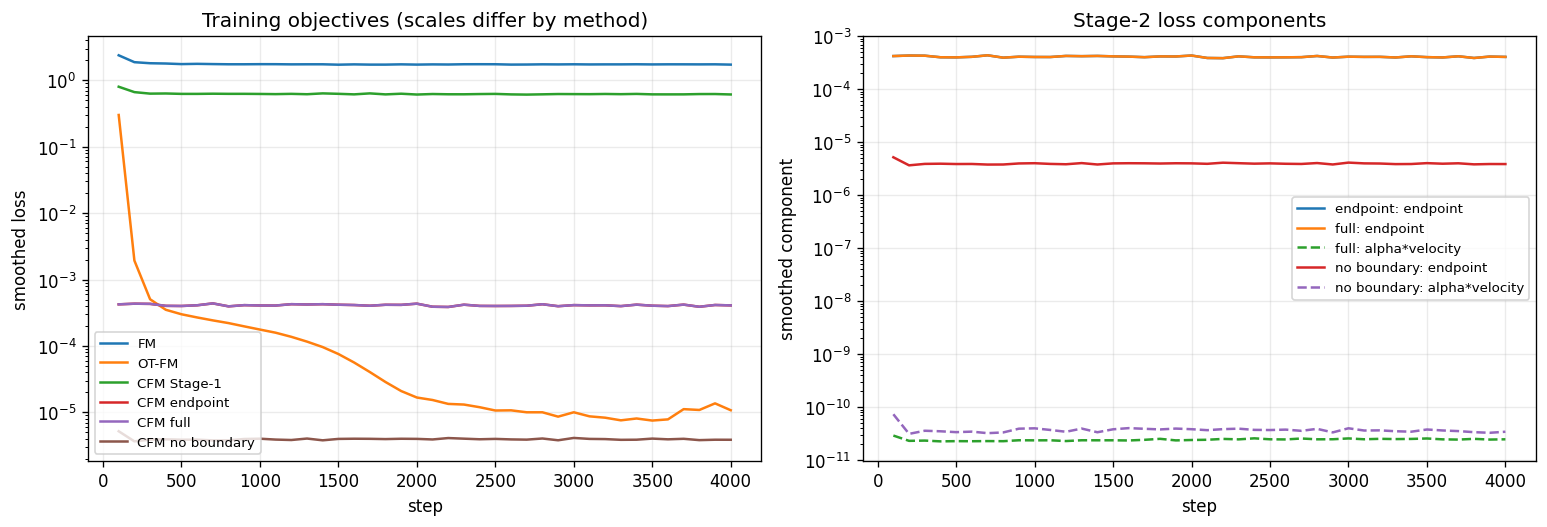

In [9]:
def smooth_curve(values, window=100):
    values = np.asarray(values)
    usable = len(values)//window*window
    means = values[:usable].reshape(-1, window).mean(axis=1)
    return np.arange(len(means))*window+window, means


histories = {
    "FM": fm_history,
    "OT-FM": ot_history,
    "CFM Stage-1": stage1_history,
    "CFM endpoint": endpoint_history,
    "CFM full": full_history,
    "CFM no boundary": no_boundary_history,
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, history in histories.items():
    x_axis, values = smooth_curve(history["total"])
    axes[0].plot(x_axis, values, label=name)
axes[0].set(title="Training objectives (scales differ by method)", xlabel="step", ylabel="smoothed loss", yscale="log")
axes[0].legend(fontsize=8)

for name, history in {
    "endpoint": endpoint_history,
    "full": full_history,
    "no boundary": no_boundary_history,
}.items():
    x_axis, endpoint_values = smooth_curve(history["endpoint"])
    _, weighted_velocity_values = smooth_curve(history["weighted_velocity"])
    axes[1].plot(x_axis, endpoint_values, label=f"{name}: endpoint")
    if np.any(weighted_velocity_values > 0):
        axes[1].plot(x_axis, weighted_velocity_values, linestyle="--", label=f"{name}: alpha*velocity")
axes[1].set(title="Stage-2 loss components", xlabel="step", ylabel="smoothed component", yscale="log")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"02_training_losses.png", dpi=170, bbox_inches="tight")
plt.show()

## 6. RK4 评估与统一指标

所有学习模型从同一批测试噪声出发，使用 128 步 RK4。报告：

- 轨迹相对自身起终点匀速连线的 `straightness`；
- 沿模型自身 ODE 轨迹的速度变化；
- 终点均值、协方差误差；
- 用样本矩拟合高斯后相对目标高斯的 Wasserstein-2 距离；
- 1 步 Euler 相对同一速度场 256 步 RK4 终点的 RMSE。

最后一项只衡量求解器误差。它很小并不代表终点分布正确。

In [10]:
@torch.no_grad()
def sample_euler(model, x0, n_steps=128):
    x = x0.clone()
    paths = [x.clone()]
    dt = 1/n_steps
    for index in range(n_steps):
        t = torch.full((len(x), 1), index*dt, device=DEVICE)
        x = x+dt*model(x, t)
        paths.append(x.clone())
    return torch.stack(paths)


@torch.no_grad()
def sample_rk4(model, x0, n_steps=128):
    x = x0.clone()
    paths = [x.clone()]
    dt = 1/n_steps
    def velocity(state, time_value):
        t = torch.full((len(state), 1), time_value, device=DEVICE)
        return model(state, t)
    for index in range(n_steps):
        t = index*dt
        k1 = velocity(x, t)
        k2 = velocity(x+dt*k1/2, t+dt/2)
        k3 = velocity(x+dt*k2/2, t+dt/2)
        k4 = velocity(x+dt*k3, t+dt)
        x = x+dt*(k1+2*k2+2*k3+k4)/6
        paths.append(x.clone())
    return torch.stack(paths)


def straightness_error(paths):
    times = torch.linspace(0, 1, len(paths), device=DEVICE)[:, None, None]
    chord = (1-times)*paths[0:1]+times*paths[-1:]
    return float((paths-chord).square().sum(dim=-1).mean())


@torch.no_grad()
def velocity_consistency_error(model, paths):
    initial_velocity = model(paths[0], torch.zeros(len(paths[0]), 1, device=DEVICE))
    total = 0.0
    for index, states in enumerate(paths):
        t = torch.full((len(states), 1), index/(len(paths)-1), device=DEVICE)
        total += (model(states, t)-initial_velocity).square().sum(dim=-1).mean()
    return float(total/len(paths))


def covariance(samples):
    centered = samples-samples.mean(dim=0, keepdim=True)
    return centered.T@centered/(len(samples)-1)


def distribution_metrics(samples):
    mean = samples.mean(dim=0)
    cov = covariance(samples)
    target_cov = torch.diag(SIGMA.square())
    mean_error = torch.linalg.norm(mean-MU)
    covariance_error = torch.linalg.norm(cov-target_cov)
    eigval, eigvec = torch.linalg.eigh(cov)
    sqrt_cov = eigvec@torch.diag(torch.sqrt(eigval.clamp_min(1e-10)))@eigvec.T
    middle_eigenvalues = torch.linalg.eigvalsh(sqrt_cov@target_cov@sqrt_cov).clamp_min(0)
    w2_squared = (mean-MU).square().sum()+torch.trace(cov)+torch.trace(target_cov)-2*torch.sqrt(middle_eigenvalues).sum()
    return float(mean_error), float(covariance_error), float(torch.sqrt(w2_squared.clamp_min(0)))


@torch.no_grad()
def one_nfe_error(model, x0):
    reference = sample_rk4(model, x0, n_steps=256)[-1]
    one_step = sample_euler(model, x0, n_steps=1)[-1]
    return float(torch.sqrt((one_step-reference).square().sum(dim=-1).mean()))


@torch.no_grad()
def evaluate_model(model, x0):
    paths = sample_rk4(model, x0, n_steps=N_STEPS)
    mean_error, cov_error, gaussian_w2 = distribution_metrics(paths[-1])
    return {
        "paths": paths,
        "straightness": straightness_error(paths),
        "velocity_consistency": velocity_consistency_error(model, paths),
        "mean_error": mean_error,
        "cov_error": cov_error,
        "gaussian_w2": gaussian_w2,
        "one_nfe_error": one_nfe_error(model, x0[:512]),
    }

In [11]:
set_seed(2026)
test_x0 = torch.randn(N_TEST, 2, device=DEVICE)
test_times = torch.linspace(0, 1, N_STEPS+1, device=DEVICE)

learned_models = {
    "FM": fm_model,
    "OT-FM": ot_model,
    "CFM endpoint": endpoint_model,
    "CFM full": full_model,
    "CFM no boundary": no_boundary_model,
}
results = {}
for name, model in learned_models.items():
    results[name] = evaluate_model(model, test_x0)


def evaluate_analytic(name, paths, velocity_function):
    mean_error, cov_error, gaussian_w2 = distribution_metrics(paths[-1])
    initial_velocity = velocity_function(paths[0], torch.zeros(len(paths[0]), 1, device=DEVICE))
    velocity_change = 0.0
    for index, states in enumerate(paths):
        t = torch.full((len(states), 1), index/(len(paths)-1), device=DEVICE)
        velocity_change += (velocity_function(states, t)-initial_velocity).square().sum(dim=-1).mean()
    # 一步 Euler 使用解析 t=0 速度；参考终点就是解析路径终点。
    one_step = paths[0]+initial_velocity
    results[name] = {
        "paths": paths,
        "straightness": straightness_error(paths),
        "velocity_consistency": float(velocity_change/len(paths)),
        "mean_error": mean_error,
        "cov_error": cov_error,
        "gaussian_w2": gaussian_w2,
        "one_nfe_error": float(torch.sqrt((one_step-paths[-1]).square().sum(dim=-1).mean())),
    }


evaluate_analytic("Analytic FM", analytic_fm_path(test_x0, test_times), analytic_fm_velocity)
evaluate_analytic("Analytic OT", analytic_ot_path(test_x0, test_times), analytic_ot_velocity)

ordered_names = ["Analytic FM", "Analytic OT", "FM", "OT-FM", "CFM endpoint", "CFM full", "CFM no boundary"]
print(
    f"{'Method':<18} {'Straight':>10} {'Velocity':>10} {'Mean':>9} "
    f"{'Cov':>9} {'Gauss-W2':>10} {'1-NFE':>9}"
)
for name in ordered_names:
    row = results[name]
    print(
        f"{name:<18} {row['straightness']:10.6f} {row['velocity_consistency']:10.6f} "
        f"{row['mean_error']:9.6f} {row['cov_error']:9.6f} "
        f"{row['gaussian_w2']:10.6f} {row['one_nfe_error']:9.6f}"
    )

Method               Straight   Velocity      Mean       Cov   Gauss-W2     1-NFE
Analytic FM          0.093997   3.820524  0.020885  0.049928   0.038385  1.687498
Analytic OT          0.000000   0.000000  0.020885  0.049928   0.038385  0.000000
FM                   0.100559   4.065454  0.016961  0.386926   0.123225  1.802751
OT-FM                0.000000   0.000040  0.021316  0.050828   0.039385  0.005529
CFM endpoint         0.059839   2.490053  0.060611  5.223133   1.341823  1.414706
CFM full             0.059840   2.490122  0.060617  5.223309   1.341846  1.414728
CFM no boundary      0.215198   6.999555  0.682114 11.006525   2.241251  2.302887


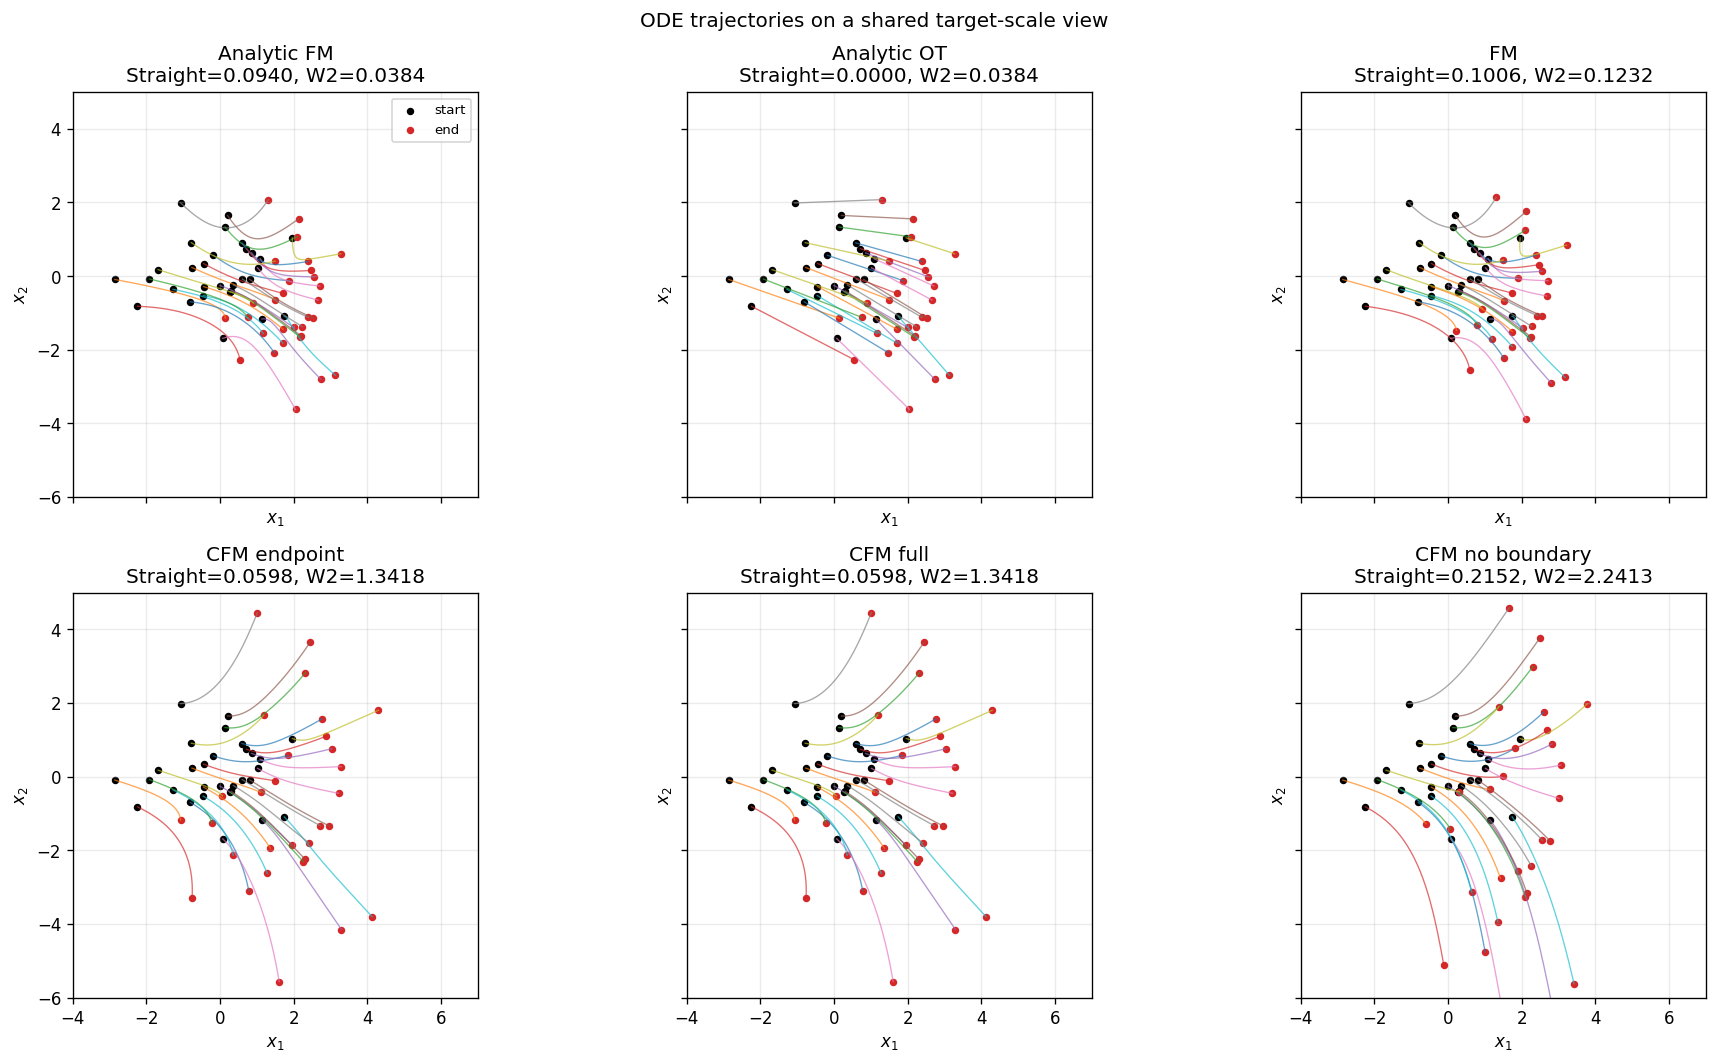

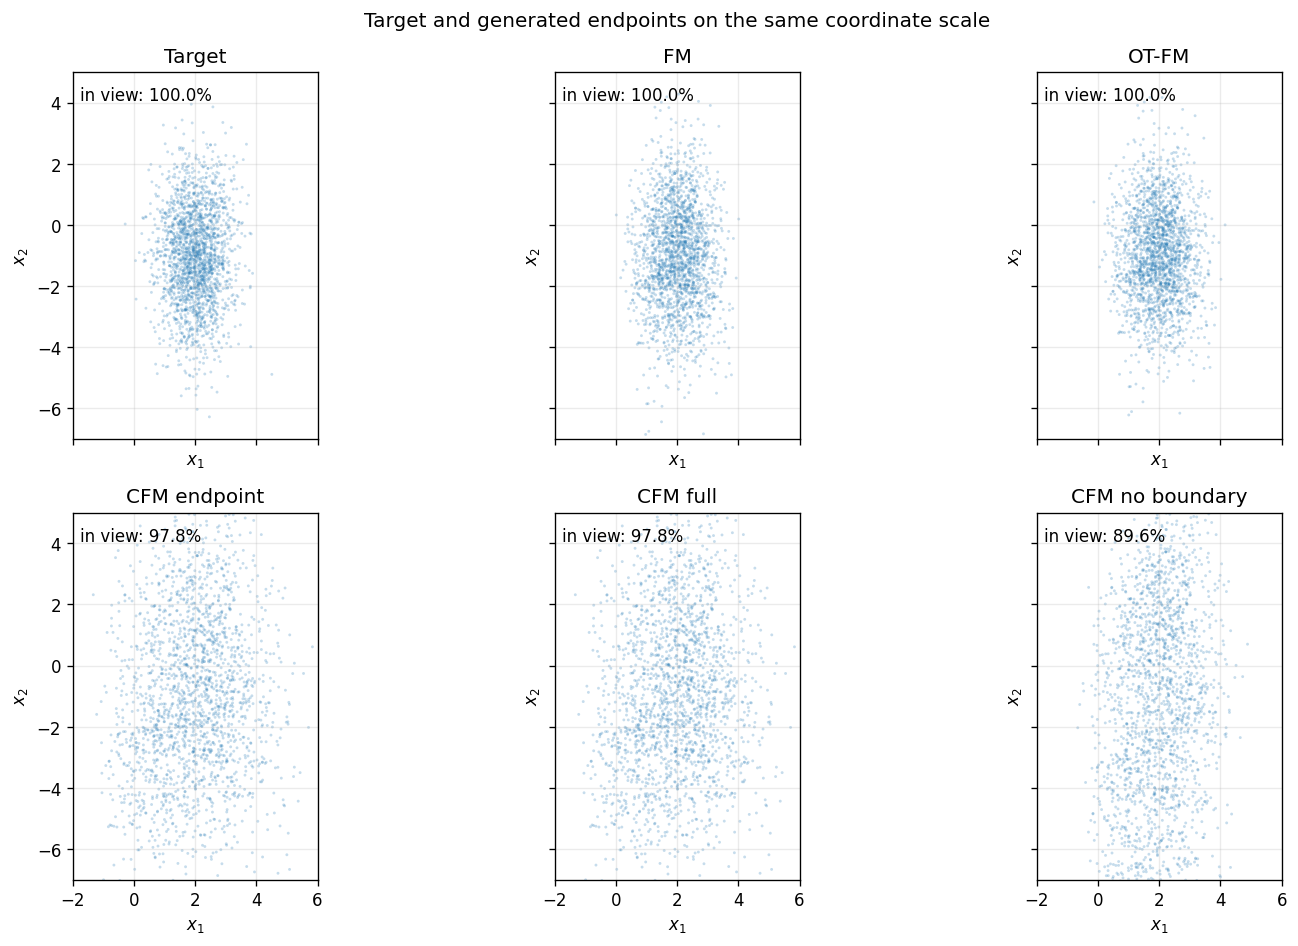

In [12]:
plot_names = ["Analytic FM", "Analytic OT", "FM", "CFM endpoint", "CFM full", "CFM no boundary"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, sharey=True)
for ax, name in zip(axes.flat, plot_names):
    paths = results[name]["paths"][:, :N_PATHS].cpu().numpy()
    for index in range(N_PATHS):
        ax.plot(paths[:, index, 0], paths[:, index, 1], linewidth=0.8, alpha=0.68)
    ax.scatter(paths[0, :, 0], paths[0, :, 1], color="black", s=12, label="start")
    ax.scatter(paths[-1, :, 0], paths[-1, :, 1], color="tab:red", s=12, label="end")
    ax.set(
        title=f"{name}\nStraight={results[name]['straightness']:.4f}, W2={results[name]['gaussian_w2']:.4f}",
        xlabel="$x_1$", ylabel="$x_2$", xlim=(-4, 7), ylim=(-6, 5),
    )
    ax.set_aspect("equal")
axes[0, 0].legend(fontsize=8)
fig.suptitle("ODE trajectories on a shared target-scale view")
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"03_ode_trajectories.png", dpi=170, bbox_inches="tight")
plt.show()

target_samples = MU+SIGMA*torch.randn_like(test_x0)
endpoint_names = ["Target", "FM", "OT-FM", "CFM endpoint", "CFM full", "CFM no boundary"]
endpoint_values = [target_samples]+[results[name]["paths"][-1] for name in endpoint_names[1:]]
fig, axes = plt.subplots(2, 3, figsize=(13, 8), sharex=True, sharey=True)
for ax, name, points_tensor in zip(axes.flat, endpoint_names, endpoint_values):
    points = points_tensor.cpu().numpy()
    inside = (points[:, 0] >= -2) & (points[:, 0] <= 6) & (points[:, 1] >= -7) & (points[:, 1] <= 5)
    ax.scatter(points[:, 0], points[:, 1], s=3, alpha=0.25, edgecolors="none")
    ax.text(0.03, 0.96, f"in view: {inside.mean():.1%}", transform=ax.transAxes, va="top")
    ax.set(title=name, xlabel="$x_1$", ylabel="$x_2$", xlim=(-2, 6), ylim=(-7, 5))
    ax.set_aspect("equal")
fig.suptitle("Target and generated endpoints on the same coordinate scale")
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"04_endpoint_distributions.png", dpi=170, bbox_inches="tight")
plt.show()

## 7. Euler NFE 敏感性

对每个学习模型，使用 256 步 RK4 得到同一速度场的参考终点，再测量不同步数 Euler 的终点 RMSE：

$$
E_{\mathrm{Euler}}(N)=
\sqrt{\mathbb E\|x_1^{\mathrm{Euler},N}-x_1^{\mathrm{RK4}}\|^2}.
$$

该图只衡量数值积分难度。需要与上一节的 Gaussian-W2 同时解读。

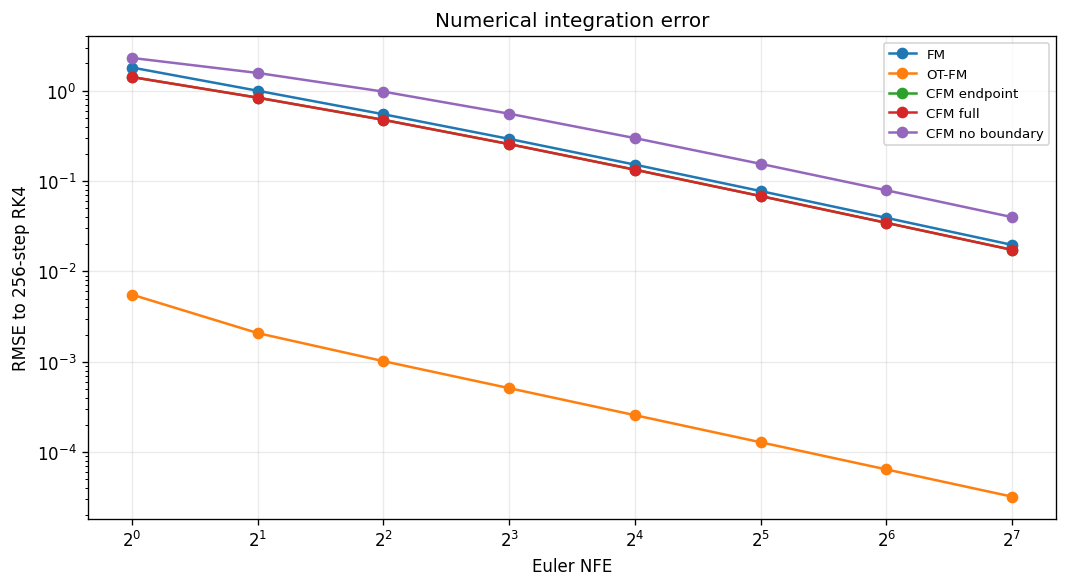

In [13]:
nfe_values = [1, 2, 4, 8, 16, 32, 64, 128]
nfe_results = {}
evaluation_subset = test_x0[:512]
with torch.no_grad():
    for name, model in learned_models.items():
        reference = sample_rk4(model, evaluation_subset, n_steps=256)[-1]
        errors = []
        for nfe in nfe_values:
            generated = sample_euler(model, evaluation_subset, n_steps=nfe)[-1]
            errors.append(float(torch.sqrt((generated-reference).square().sum(dim=-1).mean())))
        nfe_results[name] = errors

fig, ax = plt.subplots(figsize=(9, 5))
for name, errors in nfe_results.items():
    ax.plot(nfe_values, errors, marker="o", label=name)
ax.set(xscale="log", yscale="log", xlabel="Euler NFE", ylabel="RMSE to 256-step RK4", title="Numerical integration error")
ax.set_xscale("log", base=2)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"05_euler_nfe_error.png", dpi=170, bbox_inches="tight")
plt.show()

In [14]:
# 保存可复查的数值和模型参数。
metrics_to_save = {
    name: {key: value for key, value in row.items() if key != "paths"}
    for name, row in results.items()
}
artifact = {
    "config": {
        "seed": SEED, "delta": DELTA, "alpha": ALPHA,
        "boundary": BOUNDARY, "num_segments": NUM_SEGMENTS,
        "stage1_steps": STAGE1_STEPS, "stage2_steps": STAGE2_STEPS,
    },
    "field_errors_before_stage2": field_errors_before_stage2,
    "metrics": metrics_to_save,
    "nfe_values": nfe_values,
    "nfe_errors": nfe_results,
}
with open(OUTPUT_DIR/"metrics.json", "w", encoding="utf-8") as file:
    json.dump(artifact, file, indent=2, ensure_ascii=False)
torch.save({name: model.state_dict() for name, model in learned_models.items()}, OUTPUT_DIR/"models.pt")
print("Saved metrics and model weights to", OUTPUT_DIR.resolve())

Saved metrics and model weights to /home/zhangjinrui/my_program_code/Data_Processing/python/E2E/DLP/Diffuison/cfm_outputs


## 8. 本次运行结果与判断

### 第一阶段是否合格？

解析速度场验证误差为：

| 模型 | 解析速度场 MSE ↓ |
|---|---:|
| FM | 0.008598 |
| CFM Stage-1 | 0.027308 |
| OT-FM | 0.000009 |

Stage-1 的误差高于标准 FM，但已恢复主要边缘速度结构；因此第二阶段的变化可以相对同一个合格初始化进行比较。

### 统一测试结果

| 方法 | 直线性 ↓ | 速度变化 ↓ | 均值误差 ↓ | 协方差误差 ↓ | Gaussian-W2 ↓ | 1-NFE RMSE ↓ |
|---|---:|---:|---:|---:|---:|---:|
| Analytic FM | 0.093997 | 3.820524 | 0.020885 | 0.049928 | 0.038385 | 1.687498 |
| Analytic OT | 0.000000 | 0.000000 | 0.020885 | 0.049928 | 0.038385 | 0.000000 |
| FM | 0.100559 | 4.065454 | 0.016961 | 0.386926 | 0.123225 | 1.802751 |
| OT-FM | 0.000000 | 0.000040 | 0.021316 | 0.050828 | 0.039385 | 0.005529 |
| CFM endpoint | 0.059839 | 2.490053 | 0.060611 | 5.223133 | 1.341823 | 1.414706 |
| CFM full | 0.059840 | 2.490122 | 0.060617 | 5.223309 | 1.341846 | 1.414728 |
| CFM no boundary | 0.215198 | 6.999555 | 0.682114 | 11.006525 | 2.241251 | 2.302887 |

### 可以从本次实验得出的结论

1. **解析与神经网络基准正常。** independent FM 正确到达目标但轨迹弯曲；解析 OT 和 OT-FM 同时获得正确分布、直线轨迹和近零 1-NFE 误差。
2. **终点一致性确实使轨迹更直、更易积分。** 相对 FM，`CFM endpoint` 的直线性从 0.1006 降到 0.0598，速度变化和 1-NFE 误差也下降。
3. **本次变直伴随明显分布偏移。** `CFM endpoint` 的 Gaussian-W2 从 FM 的 0.1232 增至 1.3418，主要问题是协方差被显著放大。这说明自一致性改善没有同时保持正确概率输运。
4. **真实 boundary 很重要。** 去掉真实终点监督后，直线性、速度一致性和分布指标全部进一步恶化；其 Gaussian-W2 达到 2.2413。
5. **当前尺度下速度项没有产生可见作用。** `CFM full` 与 `CFM endpoint` 的结果几乎相同。训练中 $\alpha\mathcal L_{\mathrm{vel}}$ 约为 $10^{-11}$，而终点损失约为 $10^{-4}$，相差约七个数量级。这个结果说明应通过后续 $\alpha$ 扫描研究尺度，而不能仅凭名义权重判断速度项有效。

以上结论只针对单段、单随机种子、二维 MLP 和当前损失尺度。下一步适合固定 Stage-1 权重，运行 $\alpha\in\{0,10^{-6},10^{-5},10^{-4},10^{-3},10^{-2}\}$，然后再扩展到 $K=2$ 和多随机种子。

### 输出文件

- `01_analytic_coupling_paths.png`：条件直线、解析 independent 边缘流和 OT 流；
- `02_training_losses.png`：所有训练曲线及 Stage-2 损失分量；
- `03_ode_trajectories.png`：统一坐标范围的六组 ODE 轨迹；
- `04_endpoint_distributions.png`：目标与生成终点分布；
- `05_euler_nfe_error.png`：Euler NFE 相对 RK4 的积分误差；
- `metrics.json`：配置、速度场验收、完整指标和 NFE 数据；
- `models.pt`：五个学习模型的参数。